# Census income prediction (SAS)

The code is the same as `Census.sas`, cut into sections. The output under each cell is from running it in SAS. The dataset is the public UCI Adult Census Income data and is not included here.

## Import the data

In [ ]:
data SOR3008.Census;
    length
        age 8
        workclass $30
        fnlwgt 8
        education $25
        education_num 8
        marital_status $30
        occupation $30
        relationship $20
        race $25
        sex $7
        capital_gain 8
        capital_loss 8
        hours_per_week 8
        native_country $40
        income $7
    ;
    infile "/home/u64128910/SOR3008/AD.csv" dsd firstobs=2 dlm=',' missover;
    input
        age
        workclass $
        fnlwgt
        education $
        education_num
        marital_status $
        occupation $
        relationship $
        race $
        sex $
        capital_gain
        capital_loss
        hours_per_week
        native_country $
        income $;
run;

## Clean the data

In [ ]:
data SOR3008.Census_Clean;
    set SOR3008.Census;
    if workclass = '' then delete;
    if occupation = '' then delete;
    if native_country = '' then delete;
    if education = '' then delete;
    if marital_status = '' then delete;
    if relationship = '' then delete;
    if race = '' then delete;
    if sex = '' then delete;
    if income = '' then delete;
    
    * Check numeric variables;
    if age = . then delete;
    if fnlwgt = . then delete;
    if education_num = . then delete;
    if capital_gain = . then delete;
    if capital_loss = . then delete;
    if hours_per_week = . then delete;
run;

## Frequency tables

workclass         Frequency  Percent  Cumulative Frequency  Cumulative Percent
?                      1836     5.64                  1836                5.64
Federal-gov             960     2.95                  2796                8.59
Local-gov              2093     6.43                  4889               15.02
Never-worked              7     0.02                  4896               15.04
Private               22696    69.71                 27592               84.74
Self-emp-inc           1116     3.43                 28708               88.17
Self-emp-not-inc       2541     7.80                 31249               95.97
State-gov              1297     3.98                 32546               99.96
Without-pay              14     0.04                 32560              100.00


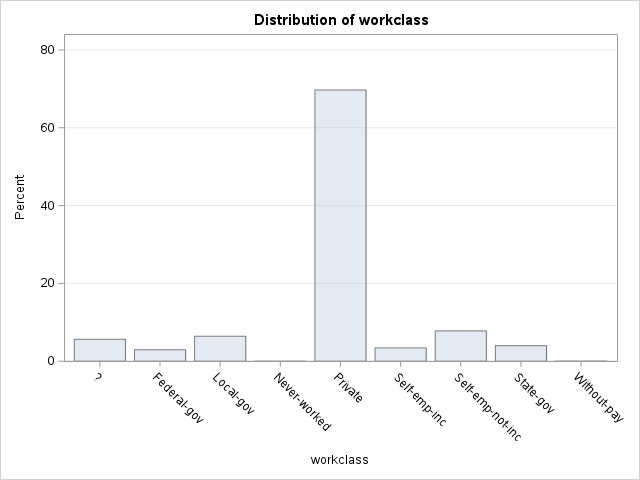

education     Frequency  Percent  Cumulative Frequency  Cumulative Percent
10th                933     2.87                   933                2.87
11th               1175     3.61                  2108                6.47
12th                433     1.33                  2541                7.80
1st-4th             168     0.52                  2709                8.32
5th-6th             333     1.02                  3042                9.34
7th-8th             646     1.98                  3688               11.33
9th                 514     1.58                  4202               12.91
Assoc-acdm         1067     3.28                  5269               16.18
Assoc-voc          1382     4.24                  6651               20.43
Bachelors          5354    16.44                 12005               36.87
Doctorate           413     1.27                 12418               38.14
HS-grad           10501    32.25                 22919               70.39
Masters            1723  

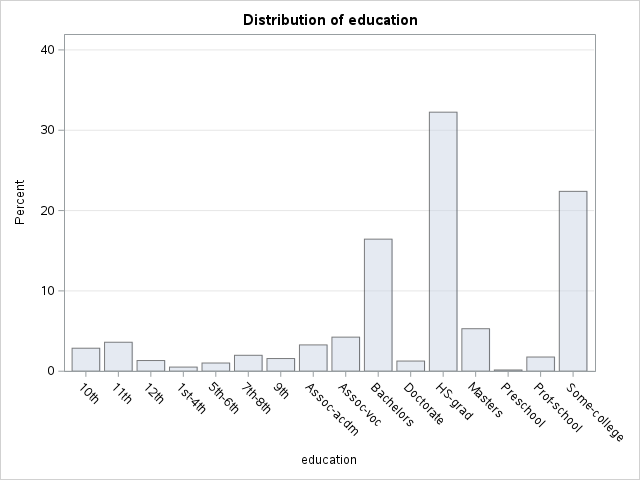

marital_status         Frequency  Percent  Cumulative Frequency  Cumulative Percent
Divorced                    4443    13.65                  4443               13.65
Married-AF-spouse             23     0.07                  4466               13.72
Married-civ-spouse         14976    46.00                 19442               59.71
Married-spouse-absent        418     1.28                 19860               61.00
Never-married              10682    32.81                 30542               93.80
Separated                   1025     3.15                 31567               96.95
Widowed                      993     3.05                 32560              100.00


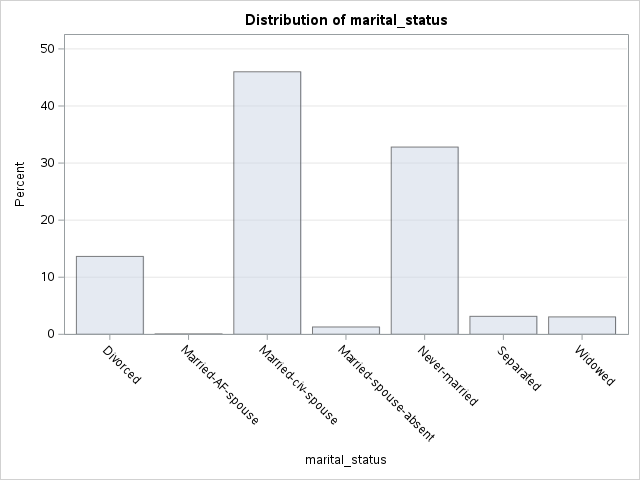

occupation         Frequency  Percent  Cumulative Frequency  Cumulative Percent
?                       1843     5.66                  1843                5.66
Adm-clerical            3769    11.58                  5612               17.24
Armed-Forces               9     0.03                  5621               17.26
Craft-repair            4099    12.59                  9720               29.85
Exec-managerial         4066    12.49                 13786               42.34
Farming-fishing          994     3.05                 14780               45.39
Handlers-cleaners       1370     4.21                 16150               49.60
Machine-op-inspct       2002     6.15                 18152               55.75
Other-service           3295    10.12                 21447               65.87
Priv-house-serv          149     0.46                 21596               66.33
Prof-specialty          4140    12.71                 25736               79.04
Protective-serv          649     1.99   

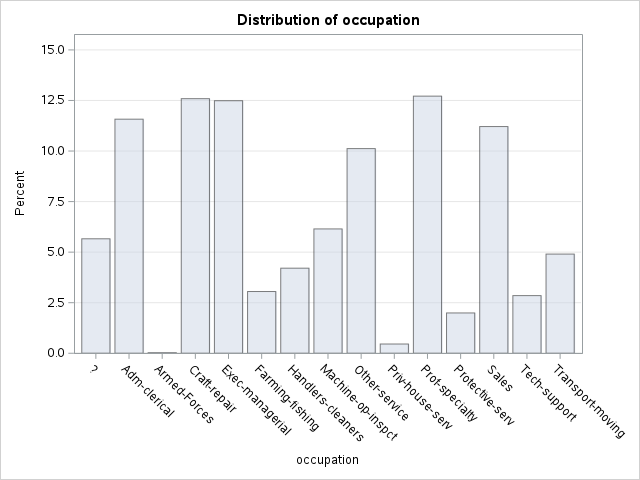

relationship    Frequency  Percent  Cumulative Frequency  Cumulative Percent
Husband             13193    40.52                 13193               40.52
Not-in-family        8304    25.50                 21497               66.02
Other-relative        981     3.01                 22478               69.04
Own-child            5068    15.57                 27546               84.60
Unmarried            3446    10.58                 30992               95.18
Wife                 1568     4.82                 32560              100.00


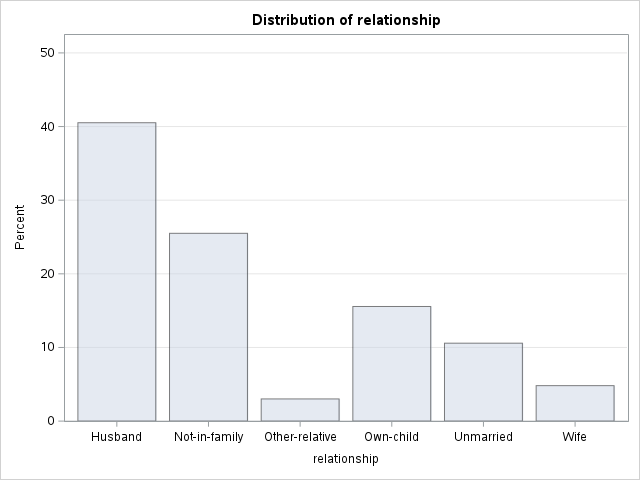

race                Frequency  Percent  Cumulative Frequency  Cumulative Percent
Amer-Indian-Eskimo        311     0.96                   311                0.96
Asian-Pac-Islander       1039     3.19                  1350                4.15
Black                    3124     9.59                  4474               13.74
Other                     271     0.83                  4745               14.57
White                   27815    85.43                 32560              100.00


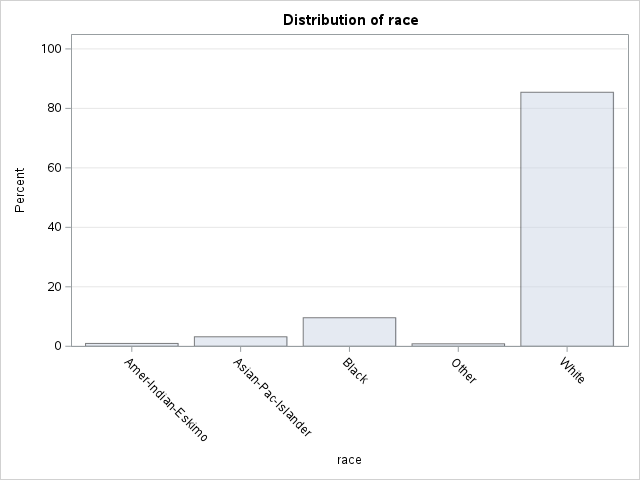

sex     Frequency  Percent  Cumulative Frequency  Cumulative Percent
Female      10771    33.08                 10771               33.08
Male        21789    66.92                 32560              100.00


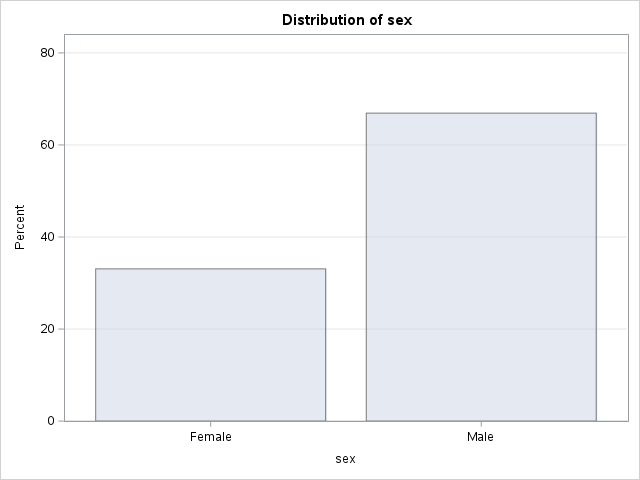

native_country      Frequency  Percent  Cumulative Frequency  Cumulative Percent
?                         583     1.79                   583                1.79
Cambodia                   19     0.06                   602                1.85
Canada                    121     0.37                   723                2.22
China                      75     0.23                   798                2.45
Columbia                   59     0.18                   857                2.63
Cuba                       95     0.29                   952                2.92
Dominican-Republic         70     0.21                  1022                3.14
Ecuador                    28     0.09                  1050                3.22
El-Salvador               106     0.33                  1156                3.55
England                    90     0.28                  1246                3.83
France                     29     0.09                  1275                3.92
Germany                   13

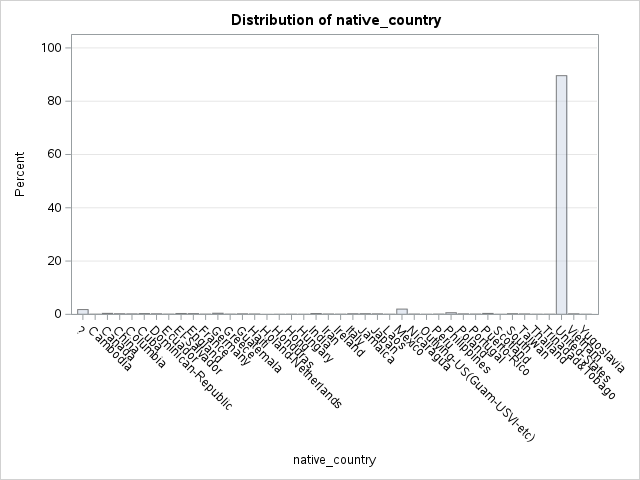

income  Frequency  Percent  Cumulative Frequency  Cumulative Percent
<=50K       24719    75.92                 24719               75.92
>50K         7841    24.08                 32560              100.00


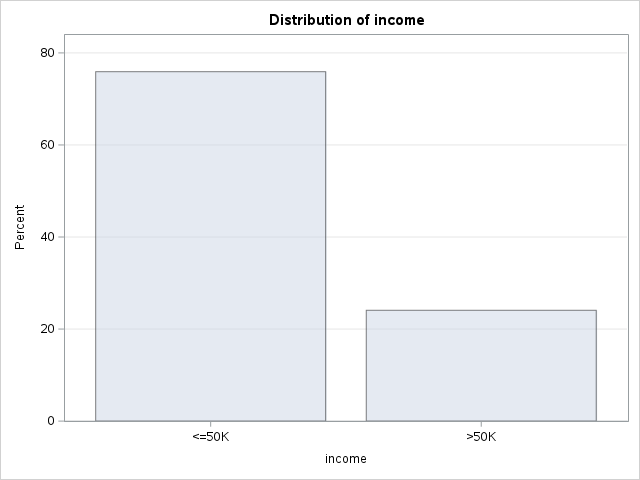

In [ ]:
proc freq data=SOR3008.Census_clean;
    tables workclass education marital_status occupation 
           relationship race sex native_country income 
           / plots=freqplot(scale=percent);
run;
data SOR3008.Census_1;
    set SOR3008.Census_clean;
    
    * Count how many "?" per record;
    q_count = (workclass = "?") + (occupation = "?") + (native_country = "?");
    
    * Income binary;
    income_binary = (income = ">50K");
run;
proc freq data=SOR3008.Census_1;
    tables q_count / missing;
    title "Number of Missing Values per Record";
run;

## Income rates by original category

In [ ]:
* Calculate overall rate;
proc means data=SOR3008.Census_1 mean n;
    var income_binary;
    format income_binary percent8.2;
run;

proc freq data=SOR3008.Census_1;
    tables q_count / missing;
    title "Number of Missing Values per Record";
run;

proc means data=SOR3008.Census_1 mean;
    class q_count;
    var income_binary;
    title "Income >50K Rate by Number of Missing Values";
run;

proc means data=SOR3008.Census_1 mean;
    class workclass;
    var income_binary;
    title "Original Workclass - Income >50K Rates";
run;

proc means data=SOR3008.Census_1 mean;
    class occupation;
    var income_binary;
    title "Original Occupation - Income >50K Rates";
run;

proc means data=SOR3008.Census_1 mean;
    class education;
    var income_binary;
    title "Original Education - Income >50K Rates";
run;

proc means data=SOR3008.Census_1 mean;
    class marital_status;
    var income_binary;
    title "Original Marital Status - Income >50K Rates";
run;

q_count  Frequency  Percent  Cumulative Frequency  Cumulative Percent
0            30161    92.63                 30161               92.63
1              563     1.73                 30724               94.36
2             1809     5.56                 32533               99.92
3               27     0.08                 32560              100.00


Analysis Variable : income_binary
Mean           N
0.2408170  32560


q_count  Frequency  Percent  Cumulative Frequency  Cumulative Percent
0            30161    92.63                 30161               92.63
1              563     1.73                 30724               94.36
2             1809     5.56                 32533               99.92
3               27     0.08                 32560              100.00


Analysis Variable : income_binary
q_count  N Obs       Mean
0        30161  0.2489307
1          563  0.2522202
2         1809  0.1033720
3           27  0.1481481


Analysis Variable : income_binary
workclass         N Obs       Mean
?                  1836  0.1040305
Federal-gov         960  0.3864583
Local-gov          2093  0.2947922
Never-worked          7          0
Private           22696  0.2186729
Self-emp-inc       1116  0.5573477
Self-emp-not-inc   2541  0.2849272
State-gov          1297  0.2721665
Without-pay          14          0


Analysis Variable : income_binary
occupation         N Obs       Mean
?                   1843  0.1036354
Adm-clerical        3769  0.1345184
Armed-Forces           9  0.1111111
Craft-repair        4099  0.2266406
Exec-managerial     4066  0.4840138
Farming-fishing      994  0.1156942
Handlers-cleaners   1370  0.0627737
Machine-op-inspct   2002  0.1248751
Other-service       3295  0.0415781
Priv-house-serv      149  0.0067114
Prof-specialty      4140  0.4490338
Protective-serv      649  0.3251156
Sales               3650  0.2693151
Tech-support         928  0.3049569
Transport-moving    1597  0.2003757


Analysis Variable : income_binary
education     N Obs       Mean
10th            933  0.0664523
11th           1175  0.0510638
12th            433  0.0762125
1st-4th         168  0.0357143
5th-6th         333  0.0480480
7th-8th         646  0.0619195
9th             514  0.0525292
Assoc-acdm     1067  0.2483599
Assoc-voc      1382  0.2612156
Bachelors      5354  0.4148300
Doctorate       413  0.7409201
HS-grad       10501  0.1595086
Masters        1723  0.5565873
Preschool        51          0
Prof-school     576  0.7343750
Some-college   7291  0.1902345


Analysis Variable : income_binary
marital_status         N Obs       Mean
Divorced                4443  0.1042089
Married-AF-spouse         23  0.4347826
Married-civ-spouse     14976  0.4468483
Married-spouse-absent    418  0.0813397
Never-married          10682  0.0459652
Separated               1025  0.0643902
Widowed                  993  0.0855992


Analysis Variable : income_binary
work_group                 N Obs      N       Mean    Std Dev  Minimum    Maximum
Federal Government           960    960  0.3864583  0.4871915        0  1.0000000
Local/State Government      3390   3390  0.2861357  0.4520203        0  1.0000000
Missing                     1836   1836  0.1040305  0.3053833        0  1.0000000
Not Working                   21     21          0          0        0          0
Private/Low Self-Employed  25237  25237  0.2253437  0.4178168        0  1.0000000
Self-Employed High Income   1116   1116  0.5573477  0.4969230        0  1.0000000


## Group the categories

In [ ]:
data SOR3008.Census_2;
    set SOR3008.Census_1;
    
    /* WORKCLASS GROUPINGS - based on income rates */
    length work_group $30;
    select (workclass);
        when ("?") work_group = "Missing";
        when ("Self-emp-inc") work_group = "Self-Employed High Income";    
        when ("Federal-gov") work_group = "Federal Government";           
        when ("Local-gov", "State-gov") work_group = "Local/State Government"; 
        when ("Self-emp-not-inc", "Private") work_group = "Private/Low Self-Employed"; 
        when ("Never-worked", "Without-pay") work_group = "Not Working";   
        otherwise work_group = "Other";
    end;
    
    * OCCUPATION GROUPINGS - based on income rates ;
    length occ_group $30;
    select (occupation);
        when ("?") occ_group = "Missing";
        when ("Exec-managerial", "Prof-specialty") occ_group = "Professional/Managerial"; 
        when ("Protective-serv", "Tech-support") occ_group = "Protective/Tech"; 
        when ("Sales", "Craft-repair") occ_group = "Sales/Crafts";       
        when ("Adm-clerical", "Transport-moving", "Machine-op-inspct") occ_group = "Admin/Transport/Labor";
        when ("Farming-fishing", "Armed-Forces") occ_group = "Farming/Military"; 
        when ("Handlers-cleaners", "Other-service") occ_group = "Service/Labor"; 
        when ("Priv-house-serv") occ_group = "Private Household";           
        otherwise occ_group = "Other";
    end;
    
    /* EDUCATION GROUPINGS - based on income rates */
    length edu_group $25;
    select (education);
        when ("Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th") 
            edu_group = "Less than High School";          
        when ("HS-grad") 
            edu_group = "HS Graduate";         
        when ("Some-college", "Assoc-acdm", "Assoc-voc") 
            edu_group = "Some College/Associate";         
        when ("Bachelors") 
            edu_group = "Bachelors";                    
        when ("Masters", "Prof-school", "Doctorate") 
            edu_group = "Graduate Degree";                 
        otherwise edu_group = "Other";
    end;
    
    /* MARITAL STATUS GROUPINGS - based on income rates */
    length marital_group $25;
    select (marital_status);
        when ("Married-civ-spouse", "Married-AF-spouse") 
            marital_group = "Married";                    
        when ("Never-married") 
            marital_group = "Never Married";            
        when ("Divorced", "Separated", "Widowed", "Married-spouse-absent") 
            marital_group = "Previously/Not Living with Spouse"; 
        otherwise marital_group = "Other";
    end;
    
    /* RACE GROUPING - simplify */
    length race_group $15;
    select (race);
        when ("White") race_group = "White";
        when ("Black") race_group = "Black";
        when ("Asian-Pac-Islander") race_group = "Asian";
        otherwise race_group = "Other";
    end;
    
    * AGE GROUPING ;
    length age_group $10;
    if age < 30 then age_group = "<30";
    else if age < 45 then age_group = "30-44";
    else if age < 60 then age_group = "45-59";
    else age_group = "60+";
    
    * HOURS GROUPING;
    length hours_group $10;
    if hours_per_week < 30 then hours_group = "Part";
    else if hours_per_week < 41 then hours_group = "Full";
    else hours_group = "Overtime";
    
    * COUNTRY GROUPING ;
    length country_group $10;
    if native_country = "?" then country_group = "Missing";
    else if native_country = "United-States" then country_group = "USA";
    else country_group = "Non-USA";
run;

## Income rates by group

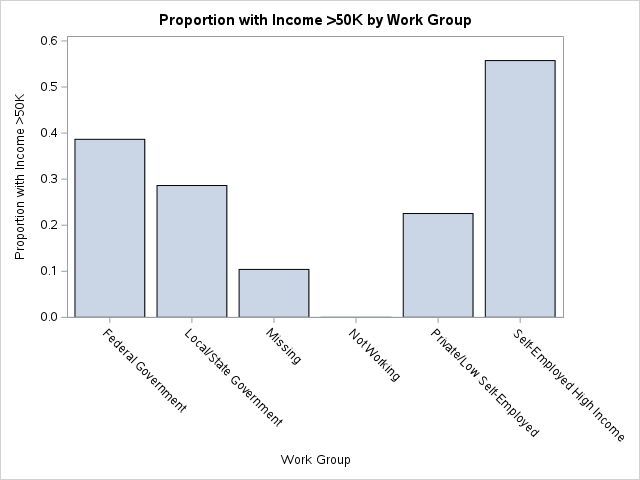

Analysis Variable : income_binary
occ_group                N Obs     N       Mean    Std Dev  Minimum    Maximum
Admin/Transport/Labor     7368  7368  0.1461726  0.3533032        0  1.0000000
Farming/Military          1003  1003  0.1156530  0.3199679        0  1.0000000
Missing                   1843  1843  0.1036354  0.3048697        0  1.0000000
Private Household          149   149  0.0067114  0.0819232        0  1.0000000
Professional/Managerial   8206  8206  0.4663661  0.4988979        0  1.0000000
Protective/Tech           1577  1577  0.3132530  0.4639634        0  1.0000000
Sales/Crafts              7749  7749  0.2467415  0.4311428        0  1.0000000
Service/Labor             4665  4665  0.0478028  0.2133716        0  1.0000000


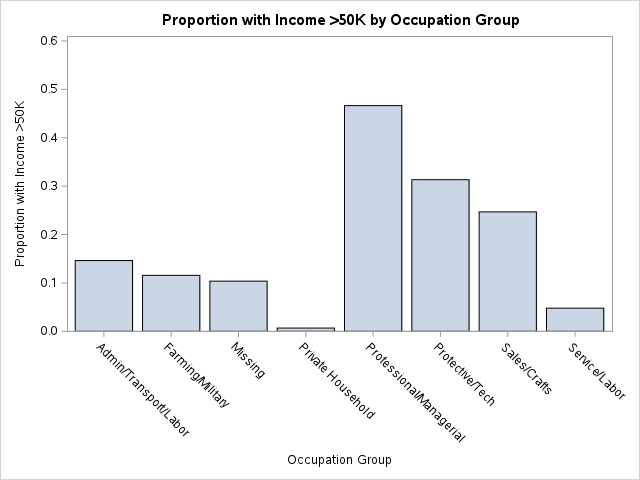

Analysis Variable : income_binary
edu_group               N Obs      N       Mean    Std Dev  Minimum    Maximum
Bachelors                5354   5354  0.4148300  0.4927387        0  1.0000000
Graduate Degree          2712   2712  0.6224189  0.4848714        0  1.0000000
HS Graduate             10501  10501  0.1595086  0.3661672        0  1.0000000
Less than High School    4253   4253  0.0573713  0.2325780        0  1.0000000
Some College/Associate   9740   9740  0.2066735  0.4049400        0  1.0000000


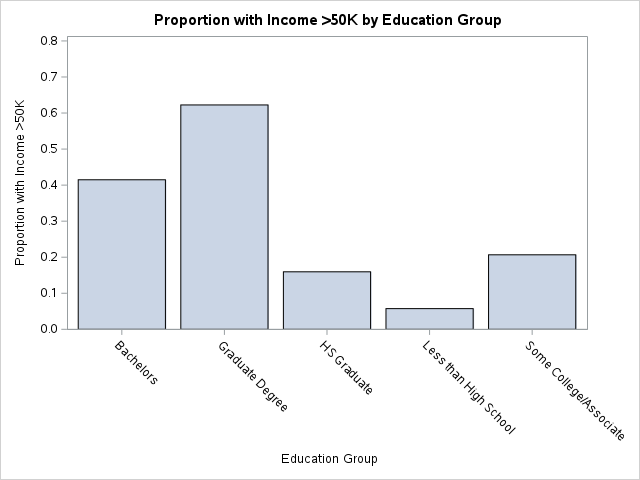

Analysis Variable : income_binary
age_group  N Obs      N       Mean    Std Dev  Minimum    Maximum
30-44      12488  12488  0.2946829  0.4559183        0  1.0000000
45-59       7717   7717  0.3884929  0.4874392        0  1.0000000
60+         2644   2644  0.2465961  0.4311111        0  1.0000000
<30         9711   9711  0.0526207  0.2232867        0  1.0000000


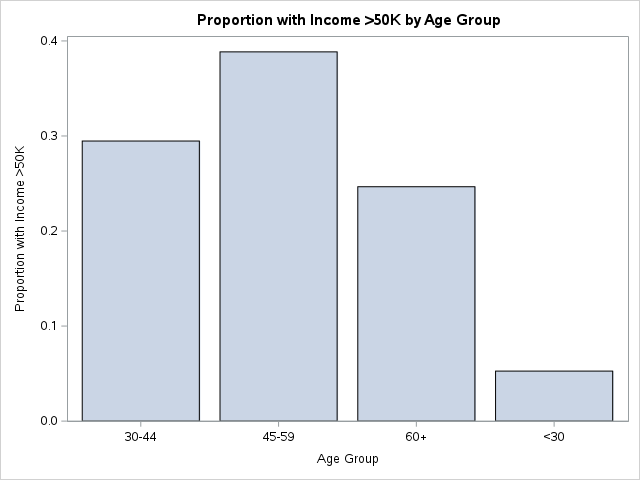

In [ ]:
* Calculate income rates by work group;
proc means data=SOR3008.Census_2;
    class work_group;
    var income_binary;
    output out=income_rates_work mean=income_rate n=count;
run;

* Plot income rates by work group;
proc sgplot data=income_rates_work;
    vbar work_group / response=income_rate;
    xaxis label="Work Group" fitpolicy=rotate;
    yaxis label="Proportion with Income >50K" values=(0 to 0.6 by 0.1);
    title "Proportion with Income >50K by Work Group";
run;

* Calculate income rates by occupation group;
proc means data=SOR3008.Census_2;
    class occ_group;
    var income_binary;
    output out=income_rates_occ mean=income_rate n=count;
run;

* Plot income rates by occupation group;
proc sgplot data=income_rates_occ;
    vbar occ_group / response=income_rate;
    xaxis label="Occupation Group" fitpolicy=rotate;
    yaxis label="Proportion with Income >50K" values=(0 to 0.6 by 0.1);
    title "Proportion with Income >50K by Occupation Group";
run;

* Calculate income rates by education group;
proc means data=SOR3008.Census_2;
    class edu_group;
    var income_binary;
    output out=income_rates_edu mean=income_rate n=count;
run;

* Plot income rates by education group;
proc sgplot data=income_rates_edu;
    vbar edu_group / response=income_rate;
    xaxis label="Education Group" fitpolicy=rotate;
    yaxis label="Proportion with Income >50K" values=(0 to 0.8 by 0.1);
    title "Proportion with Income >50K by Education Group";
run;

* Calculate income rates by age group;
proc means data=SOR3008.Census_2;
    class age_group;
    var income_binary;
    output out=income_rates_age mean=income_rate n=count;
run;

* Plot income rates by age group;
proc sgplot data=income_rates_age;
    vbar age_group / response=income_rate;
    xaxis label="Age Group";
    yaxis label="Proportion with Income >50K" values=(0 to 0.4 by 0.1);
    title "Proportion with Income >50K by Age Group";
run;

## Tests of income rate differences

sex                Method      N     Mean  Std Dev  Std Err  Minimum  Maximum
Female                     10771   0.1095   0.3122  0.00301        0   1.0000
Male                       21789   0.3058   0.4607  0.00312        0   1.0000
Diff (1-2)         Pooled         -0.1963   0.4175  0.00492
Diff (1-2)  Satterthwaite         -0.1963           0.00434


sex                Method     Mean  95% CL Mean  Std Dev  95% CL Std Dev
Female                      0.1095       0.1036   0.1154          0.3122  0.3081  0.3165
Male                        0.3058       0.2996   0.3119          0.4607  0.4564  0.4651
Diff (1-2)         Pooled  -0.1963      -0.2059  -0.1867          0.4175  0.4143  0.4207
Diff (1-2)  Satterthwaite  -0.1963      -0.2048  -0.1878


Method         Variances     DF  t Value  Pr > |t|
Pooled             Equal  32558   -39.92    <.0001
Satterthwaite    Unequal  29525   -45.28    <.0001


Equality of Variances
Method    Num DF  Den DF  F Value  Pr > F
Folded F   21788   10770     2.18  <.0001


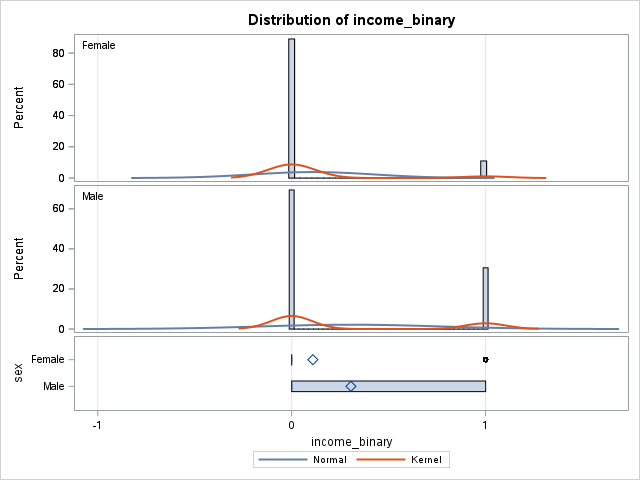

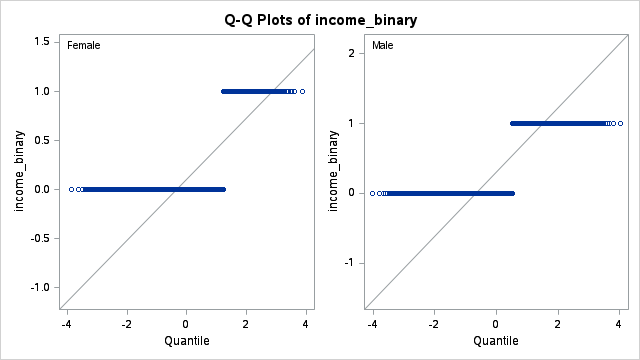

Frequency
Expected
Row Pct


Table of age_group by income
age_group  income
<=50K        >50K   Total
30-44        8808    3680  12488
           9480.7  3007.3
            70.53   29.47
45-59        4719    2998   7717
           5858.6  1858.4
            61.15   38.85
60+          1992     652   2644
           2007.3  636.72
            75.34   24.66
<30          9200     511   9711
           7372.4  2338.6
            94.74    5.26
Total       24719    7841  32560


Statistic                    DF      Value    Prob
Chi-Square                    3  3000.4734  <.0001
Likelihood Ratio Chi-Square   3  3536.0671  <.0001
Mantel-Haenszel Chi-Square    1  1988.3948  <.0001
Phi Coefficient                     0.3036
Contingency Coefficient             0.2905
Cramer's V                          0.3036


Frequency
Expected
Row Pct


Table of edu_group by income
edu_group               income
<=50K                     >50K   Total
Bachelors                 3133    2221   5354
                        4064.7  1289.3
                         58.52   41.48
Graduate Degree           1024    1688   2712
                        2058.9   653.1
                         37.76   62.24
HS Graduate               8826    1675  10501
                        7972.2  2528.8
                         84.05   15.95
Less than High School     4009     244   4253
                        3228.8  1024.2
                         94.26    5.74
Some College/Associate    7727    2013   9740
                        7394.4  2345.6
                         79.33   20.67
Total                    24719    7841  32560


Statistic                    DF      Value    Prob
Chi-Square                    4  4271.5590  <.0001
Likelihood Ratio Chi-Square   4  4075.3084  <.0001
Mantel-Haenszel Chi-Square    1  1610.4852  <.0001
Phi Coefficient                     0.3622
Contingency Coefficient             0.3406
Cramer's V                          0.3622


... (5 outputs left out)

Statistic                    DF      Value    Prob
Chi-Square                    7  3962.0519  <.0001
Likelihood Ratio Chi-Square   7  4109.2412  <.0001
Mantel-Haenszel Chi-Square    1    38.5568  <.0001
Phi Coefficient                     0.3488
Contingency Coefficient             0.3294
Cramer's V                          0.3488


Frequency
Expected
Row Pct


Table of marital_group by income
marital_group              income
<=50K                        >50K   Total
Married                      8297    6702  14999
                            11387    3612
                            55.32   44.68
Never Married               10191     491  10682
                           8109.6  2572.4
                            95.40    4.60
Previously/Not Living wit    6231     648   6879
                           5222.4  1656.6
                            90.58    9.42
Total                       24719    7841  32560


Statistic                    DF      Value    Prob
Chi-Square                    2  6509.0846  <.0001
Likelihood Ratio Chi-Square   2  7046.3867  <.0001
Mantel-Haenszel Chi-Square    1  4627.9767  <.0001
Phi Coefficient                     0.4471
Contingency Coefficient             0.4082
Cramer's V                          0.4471


In [ ]:
* Test difference in income rates between male and female;
proc ttest data=SOR3008.Census_2;
    class sex;
    var income_binary;
    where sex in ('Male', 'Female');
    title "T-Test: Income >50K Rate Difference by Sex";
run;

* Test difference in income rates between different age groups;
proc freq data=SOR3008.Census_2;
    tables age_group * income / chisq expected nocol nopercent;
run;

* Test difference in income rates between education groups;
proc freq data=SOR3008.Census_2;
    tables edu_group * income / chisq expected nocol nopercent;
run;


* Test difference in income rates between work groups;
proc freq data=SOR3008.Census_2;
    tables work_group * income / chisq expected nocol nopercent;
run;


* Test difference in income rates between occupation groups;
proc freq data=SOR3008.Census_2;
    tables occ_group * income / chisq expected nocol nopercent;
run;


* Test difference in income rates between marital status groups;
proc freq data=SOR3008.Census_2;
    tables marital_group * income / chisq expected nocol nopercent;
run;

## Export the cleaned data

In [ ]:
proc export data=SOR3008.Census_2
    outfile="/home/u64128910/SOR3008/Census.csv"
    dbms=csv
    replace;
run;

## Sample and population rates

Analysis Variable : income_binary
Mean
0.2408170


Data Summary
Number of Observations       32560
Sum of Weights          6179295876


Statistics
Variable           N      Mean  Std Errorof Mean  95% CL for Mean
income_binary  32560  0.238562          0.002686       0.23329833  0.24382633


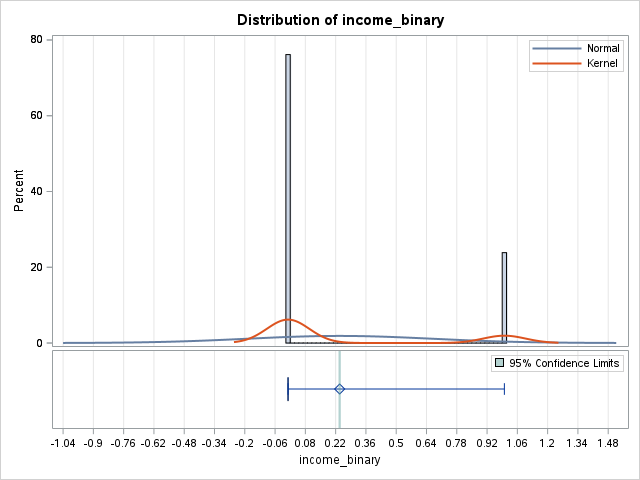

In [ ]:
proc means data=SOR3008.Census_2 mean;
    var income_binary;
    title "UNWEIGHTED: Sample Rate";
run;

proc surveymeans data=SOR3008.Census_2;
    weight fnlwgt;
    var income_binary;
    title "WEIGHTED: Population Rate";
run;

## Training and test split

In [ ]:
proc surveyselect data=SOR3008.Census_2 method=srs samprate=0.7 
                  out=CensusSplit outall;
    title "Splitting Census Data: 70% Training / 30% Test";
run;

data training test;
    set CensusSplit;
    if selected = 1 then output training;
    else output test;
run;

Selection Method  Simple Random Sampling


Input Data Set            CENSUS_2
Random Number Seed       638294911
Sampling Rate                  0.7
Sample Size                  22792
Selection Probability          0.7
Sampling Weight                  0
Output Data Set        CENSUSSPLIT


This code splits 70% training and 30% test. The poster's results use a separate 70% / 10% / 20% split, so the numbers on the poster will not match this output exactly.

## Logistic regression

Model Information
Data Set                      WORK.TRAINING
Response Variable             income_binary
Number of Response Levels                 2
Model                          binary logit
Optimization Technique     Fisher's scoring


Number of Observations Read  22792
Number of Observations Used  22792


Response Profile
Ordered Value  income_binary  Total Frequency
1                          1             5500
2                          0            17292


Class Level Information
Class                              Value  Design Variables
sex                               Female                 0
                                    Male                 1
race_group                         Asian                 1  0  0
                                   Black                 0  1  0
                                   Other                 0  0  1
                                   White                 0  0  0
work_group            Federal Government                 1  0  0  0  0
                  Local/State Government                 0  1  0  0  0
                                 Missing                 0  0  1  0  0
                             Not Working                 0  0  0  1  0
               Private/Low Self-Employed                 0  0  0  0  0
               Self-Employed High Income                 0  0  0  0  1
occ_group          Admin/Transport/Labor                 1  0  0  0  0  0  0
                        Farming/Mili

Model Convergence Status
Quasi-complete separation of data points detected.


Model Fit Statistics
Criterion  Intercept Only  Intercept and Covariates
AIC             25191.189                 15889.760
SC              25199.223                 16138.819
-2 Log L        25189.189                 15827.760


Testing Global Null Hypothesis: BETA=0
Test              Chi-Square  DF  Pr > Chi Sq
Likelihood Ratio   9361.4290  30       <.0001
Score              7943.7102  30       <.0001
Wald               4633.3400  30       <.0001


Type 3 Analysis of Effects
Effect         DF  Wald Chi-Square  Pr > Chi Sq
age_group       3         408.7012       <.0001
sex             1           2.2469       0.1339
race_group      3          16.8199       0.0008
work_group      5          72.0196       <.0001
occ_group       7         413.3561       <.0001
edu_group       4          17.7806       0.0014
marital_group   2        1831.8847       <.0001
hours_group     2         275.3571       <.0001
country_group   2          10.5513       0.0051
education_num   1          26.8865       <.0001


Analysis of Maximum Likelihood Estimates
Parameter                                 DF  Estimate  Standard Error  Wald Chi-Square  Pr > Chi Sq
Intercept                                  1   -6.9301          0.3326         434.0807       <.0001
age_group                          30-44   1    1.0818          0.0693         243.4207       <.0001
age_group                          45-59   1    1.4866          0.0736         408.0674       <.0001
age_group                            60+   1    1.1286          0.0967         136.1115       <.0001
sex                                 Male   1    0.0856          0.0571           2.2469       0.1339
race_group                         Asian   1    0.0362          0.1266           0.0820       0.7746
race_group                         Black   1   -0.1673          0.0833           4.0389       0.0445
race_group                         Other   1   -0.7475          0.2079          12.9294       0.0003
work_group            Federal Government   1    0.

Odds Ratio Estimates
Effect                                                                Point Estimate  95% Wald Confidence Limits
age_group     30-44 vs <30                                                     2.950                       2.575     3.379
age_group     45-59 vs <30                                                     4.422                       3.828     5.108
age_group     60+   vs <30                                                     3.091                       2.557     3.737
sex           Male vs Female                                                   1.089                       0.974     1.218
race_group    Asian vs White                                                   1.037                       0.809     1.329
race_group    Black vs White                                                   0.846                       0.719     0.996
race_group    Other vs White                                                   0.474                       0.315     0.712
work_

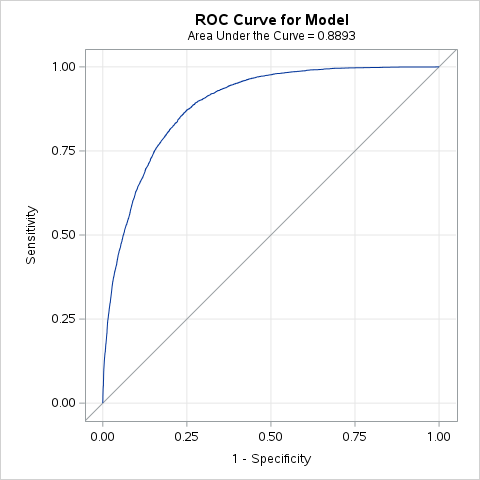

Model Convergence Status
Convergence criterion (GCONV=1E-8) satisfied.


-2 Log L  =  25189.189


Analysis of Maximum Likelihood Estimates
Parameter  DF  Estimate  Standard Error  Wald Chi-Square  Pr > Chi Sq
Intercept   1   -1.1455          0.0155        5475.3582       <.0001


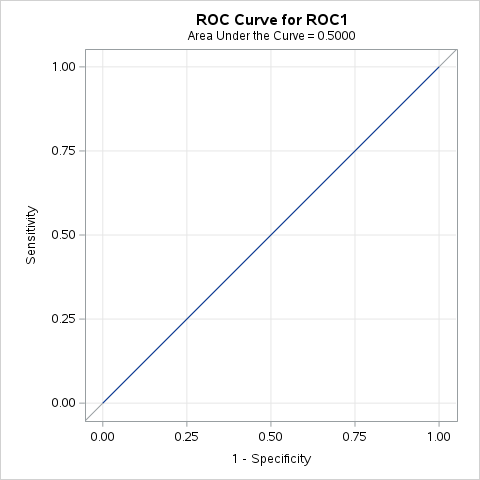

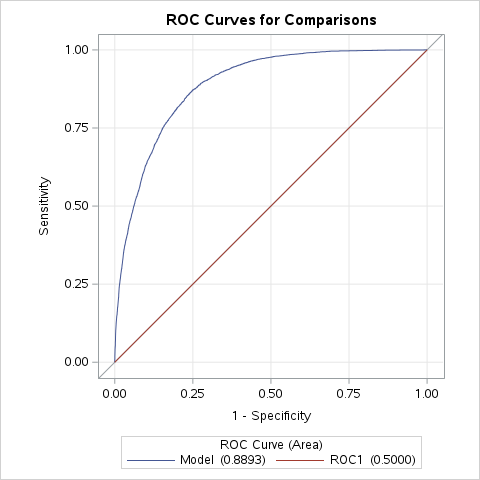

ROC Association Statistics
ROC Model   Mann-Whitney                  Somers' D   Gamma   Tau-a
Area       StandardError  95% WaldConfidence Limits
Model             0.8893                    0.00228  0.8848  0.8938  0.7786  0.7793  0.2851
ROC1              0.5000                          0  0.5000  0.5000       0       .       0


In [ ]:
proc logistic data=training descending;
    * Define categorical variables and reference groups;
    class sex (ref='Female') race_group (ref='White') 
          work_group (ref='Private/Low Self-Employed')
          occ_group (ref='Service/Labor') edu_group (ref='HS Graduate')
          marital_group (ref='Never Married') age_group (ref='<30')
          hours_group (ref='Full') country_group (ref='USA') / param=ref;
          
    model income_binary = age_group sex race_group work_group 
                         occ_group edu_group marital_group 
                         hours_group country_group education_num;        
                         
    output out=trainPredLR p=predProb;
    score data=test out=testPredLR;
    ods output Association=trainAUC_LR;
    roc;
    title "Logistic Regression: Predicting Income >50K";
run;

Apply the 0.5 threshold to the training predictions;

## Logistic regression: confusion matrices

In [ ]:
data trainEvalLR;
    set trainPredLR;
    Actual = income_binary;
    Predicted = (predProb >= 0.50);
run;

* 3. Generate the Training Confusion Matrix;
title "Confusion Matrix - Logistic Regression (TRAINING Data)";
proc freq data=trainEvalLR;
    tables Actual*Predicted / norow nocol nopct;
run;

/* Score Logistic Regression Test Data */
data lr_eval;
    set testPredLR;
    Actual = income_binary;
    Predicted = (P_1 >= 0.50); /* Probability cutoff */
run;

proc freq data=lr_eval;
   tables Actual*Predicted / norow nocol nopct;
   title "Confusion Matrix: Logistic Regression (Test Data)";
run;

Frequency


Table of Actual by Predicted
Actual  Predicted
0               1  Total
0           15912   1380  17292
1            2414   3086   5500
Total       18326   4466  22792


Frequency


Table of Actual by Predicted
Actual  Predicted
0               1  Total
0            6867    560  7427
1            1034   1307  2341
Total        7901   1867  9768


## Classification tree

Performance Information
Execution Mode     Single-Machine
Number of Threads               2


Data Access Information
Data               Engine    Role       Path
WORK.TRAINING          V9   Input  On Client
WORK.FULLTREEPRED      V9  Output  On Client


Model Information
Split Criterion Used                     Entropy
Pruning Method                   Cost-Complexity
Subtree Evaluation Criterion     Cost-Complexity
Number of Branches                             2
Maximum Tree Depth Requested                  10
Maximum Tree Depth Achieved                   10
Tree Depth                                    10
Number of Leaves Before Pruning              456
Number of Leaves After Pruning                71
Model Event Level                              1


Number of Observations Read  22792
Number of Observations Used  22792


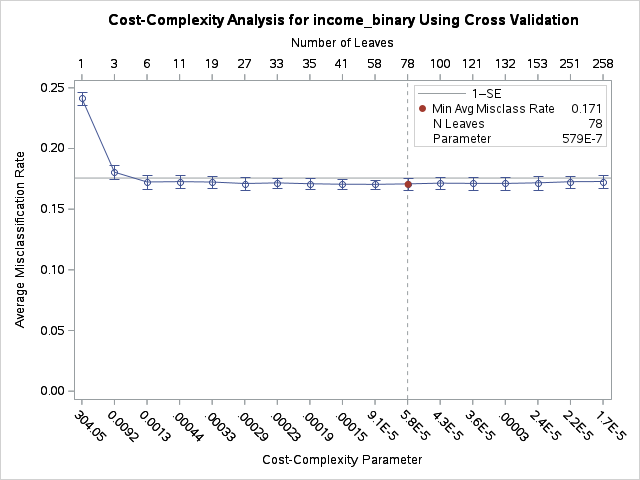

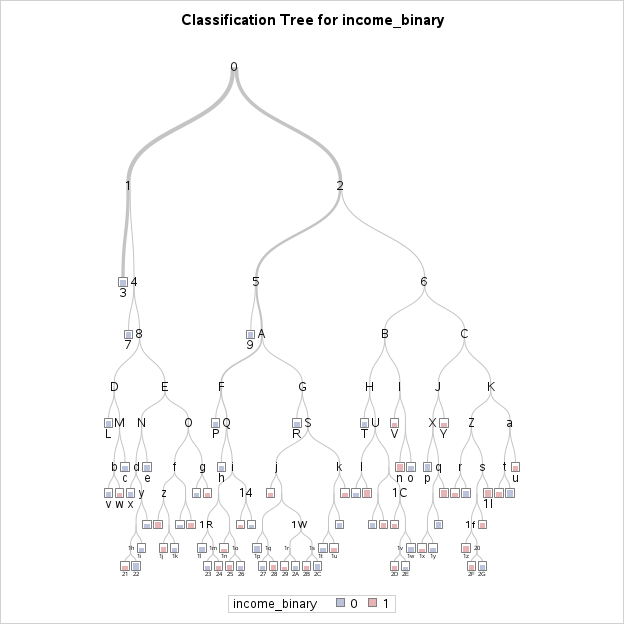

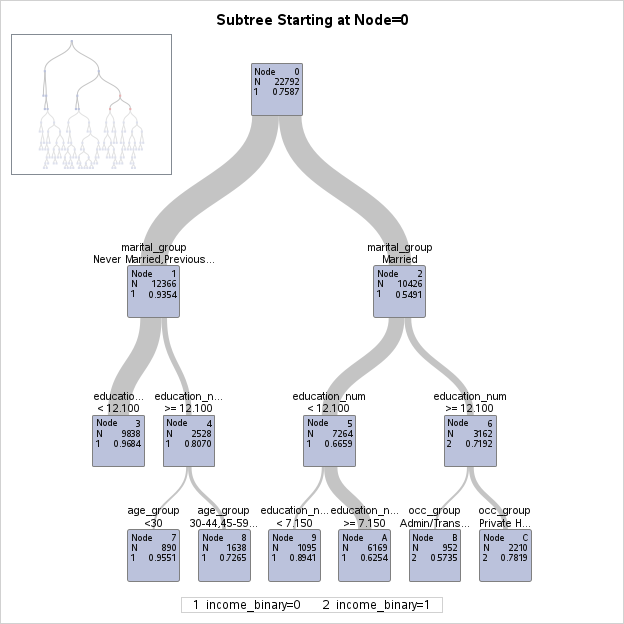

Model-Based Confusion Matrix
Actual  Predicted  Error Rate
0               1
0           15977        1315  0.0760
1            2292        3208  0.4167


Model-Based Fit Statistics for Selected Tree
NLeaves     ASE  Mis-class  Sensitivity  Specificity  Entropy    Gini     RSS     AUC
71       0.1113     0.1583       0.5833       0.9240   0.5129  0.2226  5074.0  0.8776


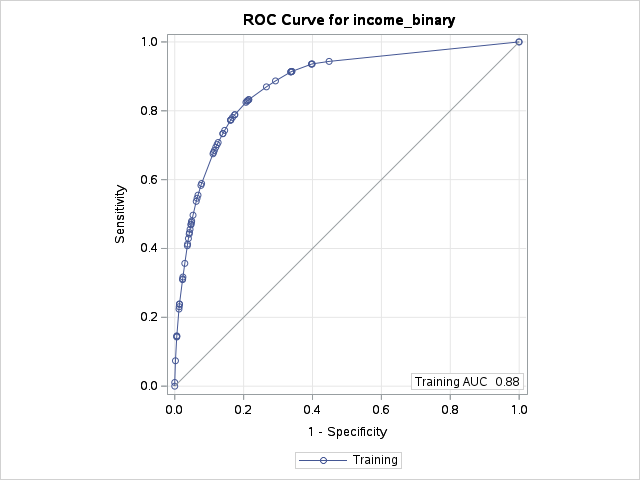

Variable Importance
Variable         Training    Count
Relative       Importance
marital_group      1.0000  41.1210   2
education_num      0.7467  30.7041  11
occ_group          0.3781  15.5483  10
age_group          0.3446  14.1691  11
hours_group        0.2493  10.2522  10
work_group         0.1334   5.4875  10
sex                0.1150   4.7299   5
edu_group          0.0983   4.0404   2
race_group         0.0831   3.4178   5
country_group      0.0761   3.1282   4


In [ ]:
proc hpsplit data=training seed=12345 maxdepth=10;
   class income_binary sex race_group work_group occ_group 
         edu_group marital_group age_group hours_group country_group;
         
   model income_binary (event='1') = education_num age_group sex race_group 
                                    work_group occ_group edu_group 
                                    marital_group hours_group country_group;
                                    
   grow entropy;
   prune costcomplexity; 
   output out=fullTreePred;
   code file='/home/u64128910/SOR3008/census_tree_model.sas'; 
   title "Building Census Classification Tree";
run;

/* Apply Tree to Test Data */

## Classification tree: test data

In [ ]:
data testTreePred;
   set test;
   %include "/home/u64128910/SOR3008/census_tree_model.sas";
run;

/* Tree Performance Evaluation */
data tree_eval;
   set testTreePred;
   Actual    = income_binary;
   Predicted = (P_income_binary1 >= 0.50);
run;

proc freq data=tree_eval;
   tables Actual*Predicted / norow nocol nopct;
   title "Confusion Matrix: Classification Tree (Test Data)";
run;

/* AUC for Logistic Regression Test Data */

Frequency


Table of Actual by Predicted
Actual  Predicted
0               1  Total
0            6801    626  7427
1            1005   1336  2341
Total        7806   1962  9768


## AUC and comparison

Model Information
Data Set                       WORK.LR_EVAL
Response Variable                    Actual
Number of Response Levels                 2
Model                          binary logit
Optimization Technique     Fisher's scoring


Number of Observations Read  9768
Number of Observations Used  9768


Response Profile
Ordered Value  Actual  Total Frequency
1                   0             7427
2                   1             2341


Model Convergence Status
Convergence criterion (GCONV=1E-8) satisfied.


Model Fit Statistics
Criterion  Intercept Only  Intercept and Covariates
AIC             10760.237                  7166.635
SC              10767.424                  7181.008
-2 Log L        10758.237                  7162.635


Testing Global Null Hypothesis: BETA=0
Test              Chi-Square  DF  Pr > Chi Sq
Likelihood Ratio   3595.6030   1       <.0001
Score              3684.6487   1       <.0001
Wald               2363.6476   1       <.0001


Analysis of Maximum Likelihood Estimates
Parameter  DF  Estimate  Standard Error  Wald Chi-Square  Pr > Chi Sq
Intercept   1   -3.0136          0.0528        3260.5564       <.0001
P_1         1    5.8850          0.1210        2363.6476       <.0001


Odds Ratio Estimates
Effect  Point Estimate  95% Wald Confidence Limits
P_1            359.585                     283.639  455.865


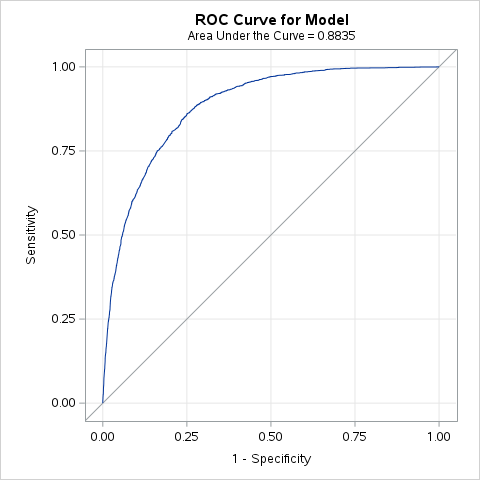

ROC Model Information
ROC Contrast Coefficients  P_1  Predicted Probability: income_binary=1


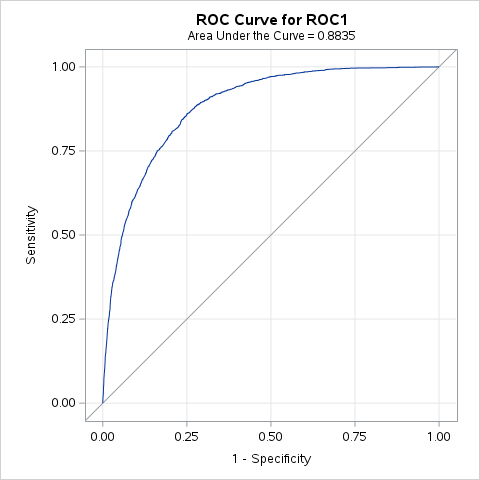

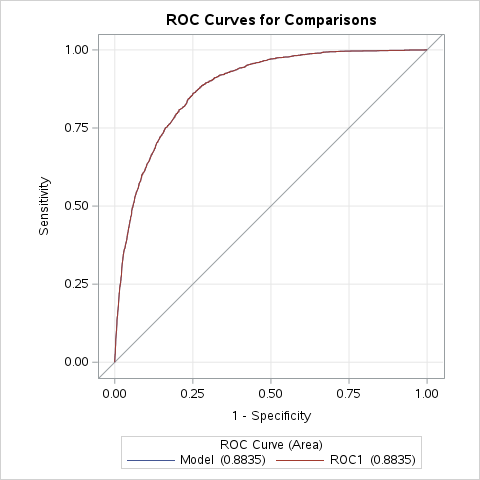

ROC Association Statistics
ROC Model   Mann-Whitney                  Somers' D   Gamma   Tau-a
Area       StandardError  95% WaldConfidence Limits
Model             0.8835                    0.00365  0.8764  0.8907  0.7670  0.7677  0.2796
ROC1              0.8835                    0.00365  0.8764  0.8907  0.7670  0.7677  0.2796


Model Information
Data Set                     WORK.TREE_EVAL
Response Variable                    Actual
Number of Response Levels                 2
Model                          binary logit
Optimization Technique     Fisher's scoring


Number of Observations Read  9768
Number of Observations Used  9768


Response Profile
Ordered Value  Actual  Total Frequency
1                   0             7427
2                   1             2341


Model Convergence Status
Convergence criterion (GCONV=1E-8) satisfied.


Model Fit Statistics
Criterion  Intercept Only  Intercept and Covariates
AIC             10760.237                  7400.871
SC              10767.424                  7415.245
-2 Log L        10758.237                  7396.871


Testing Global Null Hypothesis: BETA=0
Test              Chi-Square  DF  Pr > Chi Sq
Likelihood Ratio   3361.3666   1       <.0001
Score              3492.6840   1       <.0001
Wald               2362.7311   1       <.0001


Analysis of Maximum Likelihood Estimates
Parameter         DF  Estimate  Standard Error  Wald Chi-Square  Pr > Chi Sq
Intercept          1   -2.9032          0.0507        3281.2092       <.0001
P_income_binary1   1    5.5027          0.1132        2362.7311       <.0001


Odds Ratio Estimates
Effect            Point Estimate  95% Wald Confidence Limits
P_income_binary1         245.364                     196.539  306.318


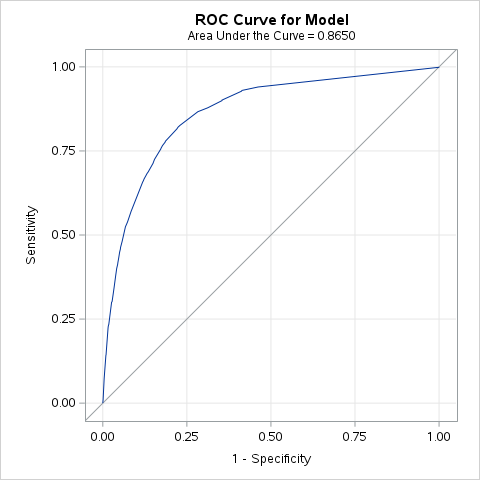

ROC Model Information
ROC Contrast Coefficients  P_income_binary1  Predicted: income_binary=1


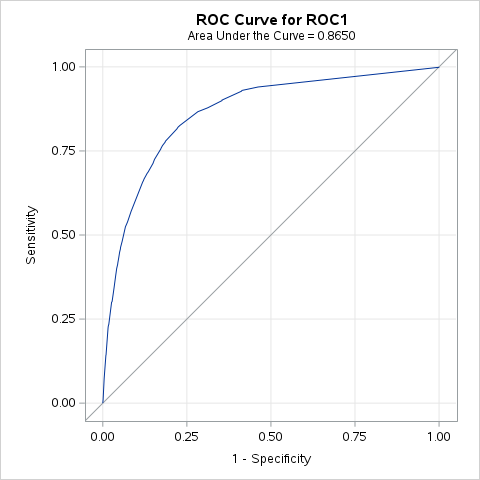

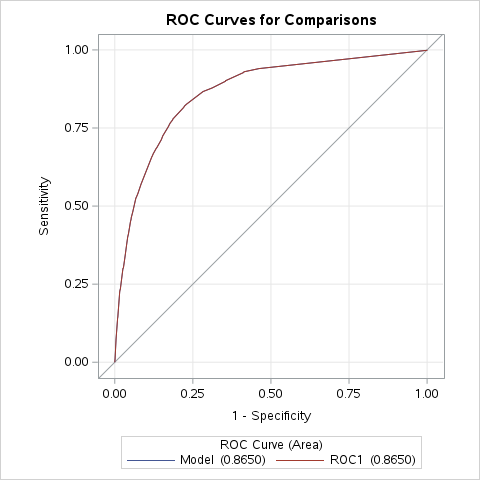

ROC Association Statistics
ROC Model   Mann-Whitney                  Somers' D   Gamma   Tau-a
Area       StandardError  95% WaldConfidence Limits
Model             0.8650                    0.00432  0.8565  0.8734  0.7299  0.7643  0.2660
ROC1              0.8650                    0.00432  0.8565  0.8734  0.7299  0.7643  0.2660


Obs  LR_AUC  Tree_AUC
1    0.8835         .
2         .    0.8650


In [ ]:
proc logistic data=lr_eval;
   model Actual(event='1') = P_1;
   roc pred=P_1;
   ods output ROCAssociation=auc_lr_final;
run;

/* AUC for Classification Tree Test Data */
proc logistic data=tree_eval;
   model Actual(event='1') = P_income_binary1;
   roc pred=P_income_binary1;
   ods output ROCAssociation=auc_tree_final;
run;

/* Combine and Print Results */
data final_comparison;
    set auc_lr_final(rename=(Area=LR_AUC) in=a)
        auc_tree_final(rename=(Area=Tree_AUC) in=b);
    where ROCModel = 'Model';
    keep LR_AUC Tree_AUC;
run;

proc print data=final_comparison;
    title "Final Coursework Comparison: Model AUC Values";
run;